# 05 - Stacking
**Stacking** trains different base models and then a **meta-model** learns how to combine their predictions.
- Base models: Random Forest (bagging), XGBoost, LightGBM and CatBoost (boosting). LightGBM / CatBoost are used if installed.
- Meta-model: Ridge regression (cross-validated regularisation).
- `cv=5`: the meta-model is trained on **out-of-fold** predictions of the base models, so it never sees predictions the base models made on their own training rows.


In [1]:
import sys, warnings
sys.path.append("..")                      # lets the notebook import the reusable code in ../src
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from src import config, preprocess as P, models as M
from src.evaluate import regression_metrics, permutation_table
sns.set_theme(style="whitegrid")
pd.options.display.float_format = "{:,.2f}".format
config.PLOT_DIR.mkdir(parents=True, exist_ok=True)

In [2]:
splits = P.load_splits()                   # same rows in every notebook (created in notebook 02)
X_tr, y_tr = P.xy(splits["train"])
X_va, y_va = P.xy(splits["val"])
print(len(X_tr), "train rows |", len(X_va), "validation rows")

3102 train rows | 665 validation rows


In [3]:
print("base models in the stack:", M.stacking_base_names())
singles = {"random_forest": M.make_random_forest, "xgboost": M.make_xgboost,
           "lightgbm": M.make_lightgbm, "catboost": M.make_catboost}
base_preds = {n: singles[n]().fit(X_tr, y_tr).predict(X_va) for n in M.stacking_base_names()}
errors = pd.DataFrame({n: y_va.values - p for n, p in base_preds.items()})
print("correlation of the base models' errors:")
errors.corr().round(3)

base models in the stack: ['random_forest', 'xgboost', 'lightgbm', 'catboost']
correlation of the base models' errors:


,random_forest,xgboost,lightgbm,catboost
random_forest,1.00,0.81,0.84,0.79
xgboost,0.81,1.00,0.83,0.98
lightgbm,0.84,0.83,1.00,0.84
catboost,0.79,0.98,0.84,1.00


### Training the Stacking Model

The stacking model is trained using the training dataset. The base models generate predictions, and the Ridge meta-model learns how to combine them. The model then predicts phone prices using the validation dataset.

The meta-model weights show how the different base models contribute to the final prediction. The alpha value represents the regularisation strength selected for Ridge Regression.

In [4]:
stack = M.make_stacking()
stack.fit(X_tr, y_tr)
p_stack = stack.predict(X_va)
meta = stack.regressor_.final_estimator_
print("meta-model weights (log-price space):")
print(pd.Series(meta.coef_, index=M.stacking_base_names()).round(3).to_string())
print("intercept = %.3f, chosen alpha = %.3g" % (meta.intercept_, meta.alpha_))

meta-model weights (log-price space):
random_forest   0.62
xgboost         0.04
lightgbm        0.10
catboost        0.27
intercept = -0.334, chosen alpha = 4.33


### Model Performance Comparison

The validation performance of the individual base models is compared with a simple average and the stacking model. MAE, RMSE and R² are used to evaluate their performance. Lower MAE and RMSE values indicate better predictions, while a higher R² indicates a better model fit.

In [5]:
p_avg = np.mean(list(base_preds.values()), axis=0)
rows = {n: regression_metrics(y_va, p) for n, p in base_preds.items()}
rows["Simple average"] = regression_metrics(y_va, p_avg)
rows["Stacking (Ridge meta)"] = regression_metrics(y_va, p_stack)
table = pd.DataFrame(rows).T
table

,MAE,RMSE,R2,MAPE_%,MedianAE
random_forest,"17,139.68","33,975.96",0.87,29.43,"8,361.19"
xgboost,"24,286.86","42,934.85",0.80,37.18,"13,455.70"
lightgbm,"21,887.53","40,909.24",0.82,38.51,"10,794.10"
catboost,"24,380.32","43,230.72",0.80,37.06,"13,182.03"
Simple average,"20,458.15","38,026.37",0.84,34.09,"10,791.18"
Stacking (Ridge meta),"17,898.16","34,494.32",0.87,30.43,"9,026.39"


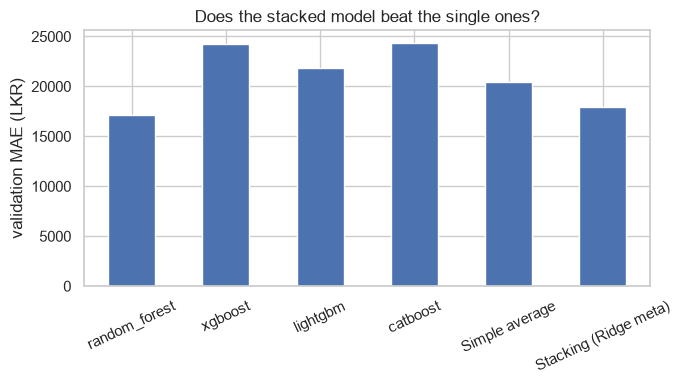

In [6]:
fig, ax = plt.subplots(figsize=(7, 4))
table["MAE"].plot.bar(ax=ax, color="#4C72B0"); ax.set_ylabel("validation MAE (LKR)")
ax.set_title("Does the stacked model beat the single ones?"); plt.xticks(rotation=25); plt.tight_layout()
plt.savefig(config.PLOT_DIR / "05_stacking_vs_base.png", dpi=150); plt.show()

## Notes
- **Stacking performance:** Stacking achieved a validation MAE of Rs. 17,898, which was 4% worse than Random Forest (Rs. 17,140). However, it performed better than the boosters and simple averaging.
- **Why stacking didn't perform better:** Base models made similar predictions, so stacking had little new information to combine. XGBoost and CatBoost had a high error correlation of 0.98.
- **Meta-model weights:** Ridge gave the highest weight to Random Forest (0.62), showing that it relied mostly on the strongest base model. Limited training data and weaker boosters also affected stacking performance.